# ЛР06. Исследование параметров text-to-image генерации

**Вариант 7:** бриф №2 — обложка подкаста о городской среде; фактор №1 — число шагов, 1 → 4; seed 101…105.

## Гипотеза и допуск — зафиксированы до запуска (27.10.2026 18:10)

**Гипотеза.** Переход с 1 на 4 шага для брифа 2 увеличит энергию границ и контраст больше чем на 10 %, а время генерации — больше чем на 20 %. Сходство CLIP с английским брифом изменится в пределах ±1,0, потому что SD Turbo обучена давать удовлетворительный результат за один шаг.

**Допуск.** CLIP — ±1,0 (абсолютное); энергия границ и контраст — ±10 % от режима A; время — ±20 % от режима A.

**Классификация вне допуска.** CLIP: рост — улучшение. Время: рост — ухудшение. Контраст: рост — улучшение (слои силуэта должны читаться как отдельные полосы). Энергия границ: рост — ухудшение (бриф требует minimal flat style). Это соответствие брифу, а не качество изображения.

**Решение.** Четыре шага окупаются, если CLIP даёт «улучшение» либо на B слои силуэта читаются как отдельные полосы, а на A — нет, и при этом CLIP не даёт «ухудшение».

Сходство CLIP считается относительно английского брифа. Вывод делается только после измерения и только для проверенных условий.

In [25]:
# Исправление среды Colab до импорта diffusers: предустановленный torchao несовместим с diffusers
# (ImportError: cannot import name 'FqnToConfig' from 'torchao.quantization'). SD Turbo и CLIP torchao не используют.
!pip list 2>/dev/null | grep -i -E "^torchao "
!pip uninstall -y -q torchao

import importlib.util
assert importlib.util.find_spec("torchao") is None, "torchao не удалён: перезапустите сеанс и выполните ячейку снова"
ENVIRONMENT_FIXES = ["torchao uninstalled before importing diffusers: ImportError FqnToConfig from torchao.quantization"]
print("torchao удалён; diffusers будет импортирован без него")

torchao удалён; diffusers будет импортирован без него


In [26]:
# Проверка GPU и фактических версий. Не продолжайте без CUDA.
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|pillow|numpy|scipy|pandas) "

import json, pathlib, platform, sys, time
from datetime import datetime, timezone
import numpy as np, scipy, torch, diffusers, transformers, PIL

assert torch.cuda.is_available(), "CUDA GPU недоступен: выберите GPU T4 в настройках Colab"
environment = {
    "execution_environment": "Google Colab",
    "gpu": torch.cuda.get_device_name(0),
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {
        "torch": torch.__version__,
        "diffusers": diffusers.__version__,
        "transformers": transformers.__version__,
        "pillow": PIL.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
    },
    "environment_fixes": ENVIRONMENT_FIXES,
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
diffusers                             0.41.0
numpy                                 2.1.3
pandas                                2.2.3
pillow                                11.3.0
scipy                                 1.16.3
torch                                 2.11.0+cu130
transformers                          5.20.2
{
  "execution_environment": "Google Colab",
  "gpu": "Tesla T4",
  "cuda_available": true,
  "cuda_runtime": "13.0",
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.41.0",
    "transformers": "5.20.2",
    "pillow": "11.3.0",
    "numpy": "2.1.3",
    "scipy": "1.16.3"
  },
  "environment_fixes": [
    "torchao uninstalled before importing diffusers: ImportError FqnToConfig from torchao.quantization"
  ],
  "started_at_utc": "2026-10-27T15:36:30.127299+00:00"
}


In [27]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Overwriting lab05_lib.py


In [28]:
%%writefile lab06_lib.py
# ЛР 6. Исследование параметров text-to-image генерации. Библиотека учебных функций.
# Требуется файл lab05_lib.py из ЛР 5 в той же папке (из него берутся модель, генерация и брифы).
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
import time
import numpy as np
import torch
from scipy import ndimage
from transformers import CLIPModel, CLIPProcessor
import lab05_lib as L

CLIP_ID = "openai/clip-vit-base-patch32"
CLIP_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
SEEDS = range(101, 106)

# Короткие запросы (только предмет) и русские переводы брифов из ЛР 5.
SHORT = ["robotic arm poster", "podcast cover about the city", "science exhibition poster",
         "ecology lecture visual, forest", "electronic music cover art"]
RU = [
    "плакат-концепт для фестиваля робототехники, светящийся силуэт механической руки, глубокий синий и янтарный цвета, чистая композиция, без текста, без логотипа, без людей",
    "квадратная обложка подкаста о городской среде, абстрактный многослойный горизонт из геометрических фигур, бирюзовый и оранжевый цвета, минималистичный плоский стиль, без текста, без людей",
    "плакат-концепт научной выставки, абстрактное созвездие соединённых узлов, тёмный фон с белыми и голубыми линиями, сбалансированная композиция, без текста, без логотипа",
    "визуал для цикла лекций по экологии, стилизованный полог леса сверху, многослойные зелёные формы, мягкий утренний свет, без текста, без людей",
    "обложка электронного музыкального релиза, шлифованная металлическая поверхность с радужными бликами, стиль макросъёмки, сильный контраст, без текста, без логотипа, без людей",
]

# Шесть факторов: (имя, изменение A -> B). Базовый режим: структурированный английский запрос, 512, 1 шаг, guidance 0.
FACTORS = ["steps_1_to_4", "size_512_to_384", "size_512_to_768", "prompt_short_to_structured", "guidance_0_to_3", "language_en_to_ru"]


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION).to("cuda").eval()
    proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)
    return model, proc


@torch.no_grad()
def clip_sim(clip, img, text):
    """Косинусное сходство изображения и текста в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=[text], images=img, return_tensors="pt", padding=True, truncation=True).to("cuda")
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return float((a * b).sum()) * 100


def luma(img):
    x = np.asarray(img.convert("RGB"), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    """Средняя длина градиента яркости (оператор Собеля, нормировка 1/8), как в ЛР 4."""
    y = luma(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma(img)))


def settings(factor, c):
    """Пара режимов (A, B) для контекста c = 0..4: словарь параметров generate() плюс текст запроса."""
    base = dict(prompt=L.BRIEFS[c], steps=1, guidance=0.0, size=512)
    a, b = dict(base), dict(base)
    if factor == "steps_1_to_4":
        b["steps"] = 4
    elif factor == "size_512_to_384":
        b["size"] = 384
    elif factor == "size_512_to_768":
        b["size"] = 768
    elif factor == "prompt_short_to_structured":
        a["prompt"] = SHORT[c]
    elif factor == "guidance_0_to_3":
        b["guidance"] = 3.0
    elif factor == "language_en_to_ru":
        b["prompt"] = RU[c]
    else:
        raise ValueError(factor)
    return a, b


def measure(pipe, clip, cfg, c, seed):
    """Одно изображение: метрики и время генерации, с; сходство CLIP считается с исходным английским брифом."""
    t0 = time.perf_counter()
    img = L.generate(pipe, cfg["prompt"], seed, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])[0]
    dt = time.perf_counter() - t0
    return dict(clip=clip_sim(clip, img, L.BRIEFS[c]), edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def variant_summary(pipe, clip, n, seeds=SEEDS):
    """Вариант n = 1..30: контекст c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k], c)
    A = {m: [] for m in ("clip", "edge", "contrast", "seconds")}
    B = {m: [] for m in A}
    for cfg in (a_cfg, b_cfg):  # прогрев: первый вызов с новым размером и числом шагов медленнее
        L.generate(pipe, cfg["prompt"], 0, steps=cfg["steps"], guidance=cfg["guidance"], size=cfg["size"])
    for s in seeds:
        ma, _ = measure(pipe, clip, a_cfg, c, s)
        mb, _ = measure(pipe, clip, b_cfg, c, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Overwriting lab06_lib.py


In [29]:
%%writefile lab06_demo.py
# ЛР 6, демонстрационный вариант 1: бриф «афиша фестиваля робототехники» × число шагов (1 → 4), серия seed 101…105.
import lab05_lib as L
import lab06_lib as M

pipe = L.load_pipe()
clip = M.load_clip()
res = M.variant_summary(pipe, clip, 1)
print("Вариант", res["variant"], "фактор", res["factor"])
for m, a, s, b, d, ratio, sig in res["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

# Намеренная ошибка: ожидание, что guidance_scale = 1.0 «включает» guidance у SD Turbo.
p = L.BRIEFS[0]
x0 = L.generate(pipe, p, 101, guidance=0.0)[0]
x1 = L.generate(pipe, p, 101, guidance=1.0)[0]
print("guidance 1.0: результат совпал с guidance 0.0 бит в бит:", L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)), "| CFG активен:", pipe.do_classifier_free_guidance)
x3 = L.generate(pipe, p, 101, guidance=3.0)[0]
print("guidance 3.0: CFG активен:", pipe.do_classifier_free_guidance, "| PSNR относительно guidance 0.0, дБ:", round(L.psnr_db(x0, x3), 2))


Overwriting lab06_demo.py


In [30]:
# Фиксированные параметры варианта (совпадают с configs/run_config.json) и сверка библиотек.
import hashlib, math
import pandas as pd
from IPython.display import display
import lab05_lib as L
import lab06_lib as M

VARIANT = 7
BRIEF = 2
FACTOR = "steps_1_to_4"
SEEDS = [101, 102, 103, 104, 105]
TOLERANCE = {"clip": ("abs", 1.0), "edge": ("rel", 0.10), "contrast": ("rel", 0.10), "seconds": ("rel", 0.20)}
DIRECTION = {"clip": +1, "edge": -1, "contrast": +1, "seconds": -1}  # +1: рост — улучшение, -1: рост — ухудшение
HYPOTHESIS_RECORDED_AT = "27.10.2026 18:10"
EXPECTED_SHA256 = {
    "lab05_lib.py": "4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a",
    "lab06_lib.py": "c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8",
    "lab06_demo.py": "6bd455ea028a475f6d21593b6f969446b676a3627ab496fd7f125394361edf4a",
}

c, k = (VARIANT - 1) // 6, (VARIANT - 1) % 6
assert (c + 1, M.FACTORS[k]) == (BRIEF, FACTOR)
assert list(M.SEEDS) == SEEDS
assert L.MODEL_ID == "stabilityai/sd-turbo" and L.REVISION == "b261bac6fd2cf515557d5d0707481eafa0485ec2"
assert M.CLIP_ID == "openai/clip-vit-base-patch32" and M.CLIP_REVISION == "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"

library_sha256 = {name: hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest() for name in EXPECTED_SHA256}
assert library_sha256 == EXPECTED_SHA256, library_sha256

PROMPT = L.BRIEFS[c]
A_CFG, B_CFG = M.settings(FACTOR, c)
changed = sorted(key for key in A_CFG if A_CFG[key] != B_CFG[key])
assert changed == ["steps"], changed

root = pathlib.Path(".")
artifacts = root / "artifacts"
reports = root / "reports"
for path in [artifacts / "demo", reports]:
    path.mkdir(parents=True, exist_ok=True)

print("Режим A:", A_CFG)
print("Режим B:", B_CFG)
print("Изменённое поле:", changed)
print("SHA-256 библиотек совпали с методичкой:", library_sha256 == EXPECTED_SHA256)

Режим A: {'prompt': 'square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people', 'steps': 1, 'guidance': 0.0, 'size': 512}
Режим B: {'prompt': 'square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people', 'steps': 4, 'guidance': 0.0, 'size': 512}
Изменённое поле: ['steps']
SHA-256 библиотек совпали с методичкой: True


## Демонстрационный вариант 1

Код `lab06_demo.py` из раздела 6.2 методички выполняется без изменений: бриф 1 × число шагов 1 → 4 и намеренная ошибка с `guidance_scale = 1.0`. Затем результат сверяется с таблицей 6.3 методички.

In [31]:
# Демонстрационный вариант 1: lab06_demo.py выполняется целиком, его переменные (res, x0, x1, x3, pipe, clip) остаются в сеансе.
demo_started = time.perf_counter()
%run lab06_demo.py
demo_seconds = time.perf_counter() - demo_started
print({"demo_seconds": round(demo_seconds, 2)})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Вариант 1 фактор steps_1_to_4
clip      A=30.7979 s=1.4309 B=30.2920 d=-0.5059 |d|/s=0.35 2s=нет
edge      A=0.0457 s=0.0070 B=0.0920 d=+0.0463 |d|/s=6.65 2s=да
contrast  A=0.1923 s=0.0225 B=0.2779 d=+0.0856 |d|/s=3.80 2s=да
seconds   A=0.3570 s=0.0923 B=0.6253 d=+0.2683 |d|/s=2.91 2s=да
guidance 1.0: результат совпал с guidance 0.0 бит в бит: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно guidance 0.0, дБ: 11.61
{'demo_seconds': 28.29}


In [32]:
# Сверка демонстрационного варианта с таблицей 6.3 и разделом 6.4 методички.
def jnum(value):
    return value if math.isfinite(value) else ("inf" if value > 0 else "-inf")

DEMO_REFERENCE = {  # A, s, B, Δ из таблицы 6.3; точность — как в методичке
    "clip": (30.796, 1.394, 30.292, -0.504, 3),
    "edge": (0.0457, 0.0069, 0.0920, 0.0463, 4),
    "contrast": (0.1923, 0.0226, 0.2778, 0.0855, 4),
    "seconds": (0.2854, 0.0027, 0.5266, 0.2412, 4),
}
demo_rows = []
for m, a, s, b, d, ratio, sig in res["rows"]:
    ra, rs, rb, rd, digits = DEMO_REFERENCE[m]
    demo_rows.append({
        "metric": m, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(ratio), "sig_2s": sig,
        "A_ref": ra, "B_ref": rb, "d_ref": rd,
        "matches_reference": m != "seconds" and round(a, digits) == ra and round(b, digits) == rb,
    })
demo_error = {
    "guidance_1_equals_0_bitwise": L.sha(L.png_bytes(x0)) == L.sha(L.png_bytes(x1)),
    "psnr_guidance_3_vs_0_db": jnum(L.psnr_db(x0, x3)),
    "psnr_reference_db": 11.6,
}
demo_result = {"variant": res["variant"], "factor": res["factor"], "rows": demo_rows,
               "intentional_error": demo_error, "demo_seconds": round(demo_seconds, 2)}
(artifacts / "demo" / "demo_variant01.json").write_text(
    json.dumps(demo_result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(demo_rows).round(4))
print(json.dumps(demo_error, ensure_ascii=False))
print("Время в демо не сверяется: оно зависит от состояния GPU.")

,metric,A,s,B,d,ratio,sig_2s,A_ref,B_ref,d_ref,matches_reference
0,clip,30.7979,1.4309,30.2920,-0.5059,0.3535,False,30.7960,30.2920,-0.5040,False
1,edge,0.0457,0.0070,0.0920,0.0463,6.6540,True,0.0457,0.0920,0.0463,True
2,contrast,0.1923,0.0225,0.2779,0.0856,3.8044,True,0.1923,0.2778,0.0855,False
3,seconds,0.3570,0.0923,0.6253,0.2683,2.9066,True,0.2854,0.5266,0.2412,False


{"guidance_1_equals_0_bitwise": true, "psnr_guidance_3_vs_0_db": 11.605078740312596, "psnr_reference_db": 11.6}
Время в демо не сверяется: оно зависит от состояния GPU.


## Вариант 7: бриф 2 × число шагов 1 → 4

In [33]:
# Загрузка моделей для варианта 7; после демо веса берутся из локального кэша Hugging Face.
import gc
del pipe, clip
gc.collect(); torch.cuda.empty_cache()

load_started = time.perf_counter()
pipe = L.load_pipe()
pipe_load_seconds = time.perf_counter() - load_started

clip_started = time.perf_counter()
clip = M.load_clip()
clip_load_seconds = time.perf_counter() - clip_started
print({"pipe_load_seconds": round(pipe_load_seconds, 2), "clip_load_seconds": round(clip_load_seconds, 2)})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{'pipe_load_seconds': 3.98, 'clip_load_seconds': 1.96}


In [34]:
# Обязательный вызов из методички: M.variant_summary(pipe, clip, 7) — серия seed 101…105 для режимов A и B.
summary_started = time.perf_counter()
summary = M.variant_summary(pipe, clip, VARIANT)
summary_seconds = time.perf_counter() - summary_started
assert summary["variant"] == VARIANT and summary["ctx"] == BRIEF and summary["factor"] == FACTOR

print("Вариант", summary["variant"], "фактор", summary["factor"])
for m, a, s, b, d, ratio, sig in summary["rows"]:
    print(f"{m:9s} A={a:.4f} s={s:.4f} B={b:.4f} d={d:+.4f} |d|/s={ratio:.2f} 2s={'да' if sig else 'нет'}")

METRIC_NAMES = {"clip": "сходство CLIP", "edge": "энергия границ", "contrast": "контраст", "seconds": "время, с"}
metric_rows = [{"metric": m, "A": a, "s": s, "B": b, "d": d, "ratio": jnum(ratio), "sig_2s": sig}
               for m, a, s, b, d, ratio, sig in summary["rows"]]
metrics = {
    "variant": VARIANT, "brief": BRIEF, "factor": FACTOR, "seeds": SEEDS,
    "mode_a": A_CFG, "mode_b": B_CFG, "clip_reference_text": PROMPT,
    "rows": metric_rows, "summary_seconds": round(summary_seconds, 2),
}
(artifacts / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame([{"метрика": METRIC_NAMES[r["metric"]], "A (1 шаг)": r["A"], "s": r["s"], "B (4 шага)": r["B"],
                       "Δ": r["d"], "|Δ|/s": r["ratio"], "|Δ| > 2s": "да" if r["sig_2s"] else "нет"}
                      for r in metric_rows]).round(4))

Вариант 7 фактор steps_1_to_4
clip      A=34.0965 s=1.8301 B=32.6521 d=-1.4444 |d|/s=0.79 2s=нет
edge      A=0.0417 s=0.0126 B=0.0653 d=+0.0237 |d|/s=1.87 2s=нет
contrast  A=0.1673 s=0.0159 B=0.2463 d=+0.0790 |d|/s=4.98 2s=да
seconds   A=0.3290 s=0.0154 B=0.5894 d=+0.2605 |d|/s=16.92 2s=да


,метрика,A (1 шаг),s,B (4 шага),Δ,|Δ|/s,|Δ| > 2s
0,сходство CLIP,34.0965,1.8301,32.6521,-1.4444,0.7893,нет
1,энергия границ,0.0417,0.0126,0.0653,0.0237,1.8729,нет
2,контраст,0.1673,0.0159,0.2463,0.0790,4.9816,да
3,"время, с",0.3290,0.0154,0.5894,0.2605,16.9212,да


,mode,seed,clip,edge,contrast,seconds
0,A,101,35.1774,0.0469,0.1607,0.3671
1,B,101,32.6114,0.0710,0.2432,0.6783
2,A,102,31.3713,0.0461,0.1622,0.4846
3,B,102,32.4743,0.0827,0.2742,0.7032
4,A,103,34.7457,0.0553,0.1954,0.3345
5,B,103,33.5038,0.0807,0.2741,0.5926
6,A,104,33.2004,0.0383,0.1619,0.3204
7,B,104,31.9671,0.0670,0.2548,0.5805
8,A,105,35.9879,0.0218,0.1564,0.3252
9,B,105,32.7037,0.0253,0.1852,0.5800


Макс. расхождение средних со вторым проходом: {'clip': 0.0, 'edge': 0.0, 'contrast': 0.0}


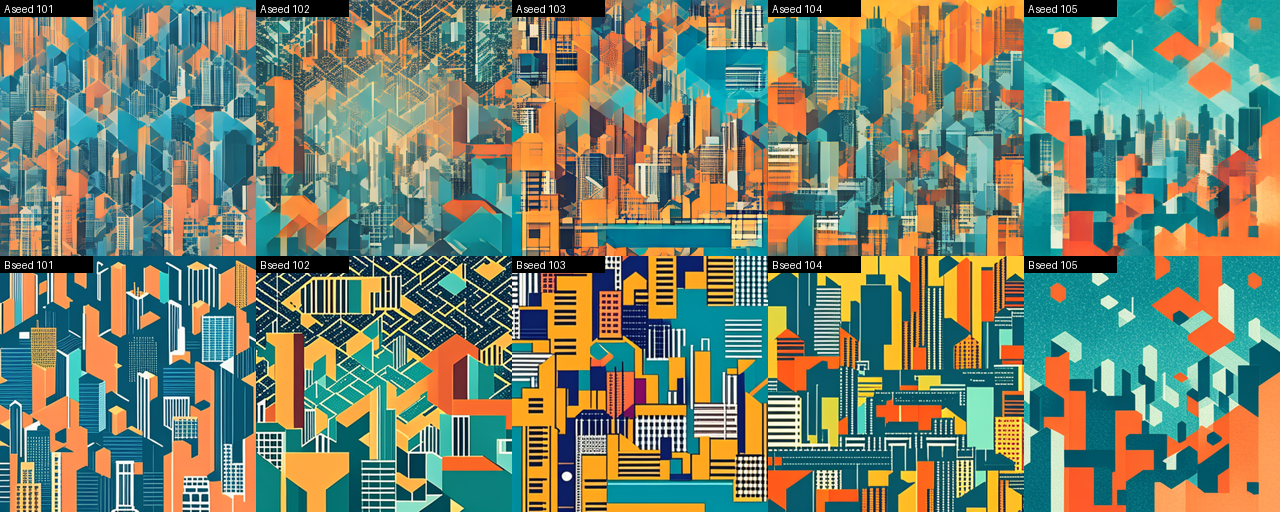

In [35]:
# Значения по каждому seed (повторный проход тем же M.measure) и проверка, что CLIP, энергия и контраст детерминированы.
from PIL import Image, ImageDraw

per_seed, images = [], {}
for seed in SEEDS:
    for mode, cfg in (("A", A_CFG), ("B", B_CFG)):
        values, image = M.measure(pipe, clip, cfg, c, seed)
        images[(mode, seed)] = image
        per_seed.append({"mode": mode, "seed": seed, **values, "sha256": L.sha(L.png_bytes(image))})
per_seed_df = pd.DataFrame(per_seed)
per_seed_df.to_csv(artifacts / "per_seed_metrics.csv", index=False)
display(per_seed_df.drop(columns="sha256").round(4))

summary_means = {m: (a, b) for m, a, s, b, *_ in summary["rows"]}
deterministic_max_abs_diff = {
    m: float(max(abs(np.mean(per_seed_df[per_seed_df["mode"] == "A"][m]) - summary_means[m][0]),
                 abs(np.mean(per_seed_df[per_seed_df["mode"] == "B"][m]) - summary_means[m][1])))
    for m in ("clip", "edge", "contrast")
}
print("Макс. расхождение средних со вторым проходом:", deterministic_max_abs_diff)

# Лист всех пяти seed: верхний ряд — A (1 шаг), нижний — B (4 шага).
tile = 256
seeds_sheet = Image.new("RGB", (tile * len(SEEDS), tile * 2), "white")
draw = ImageDraw.Draw(seeds_sheet)
for col, seed in enumerate(SEEDS):
    for row, mode in enumerate(("A", "B")):
        seeds_sheet.paste(images[(mode, seed)].resize((tile, tile)), (col * tile, row * tile))
        draw.rectangle([col * tile, row * tile, col * tile + 92, row * tile + 16], fill="black")
        draw.text((col * tile + 4, row * tile + 3), f"{mode} seed {seed}", fill="white")
seeds_sheet.save(artifacts / "comparison_all_seeds.png")
for mode in ("A", "B"):
    images[(mode, 101)].save(artifacts / f"seed101_{mode}.png")
seeds_sheet

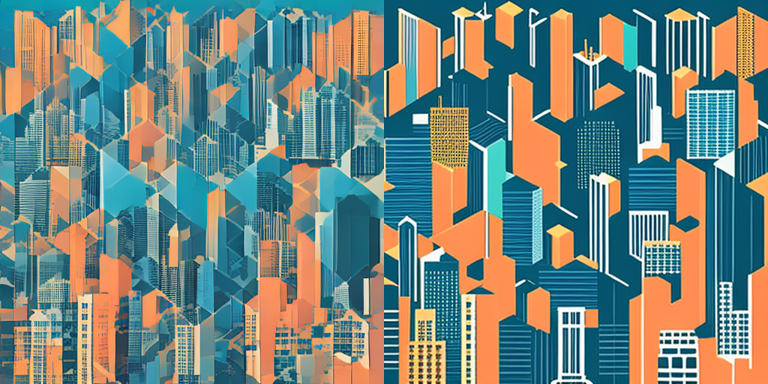

In [36]:
# Сравнительный лист для seed 101 — код раздела 6.2 методички, N = 7.
from PIL import Image
N = 7
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = M.settings(M.FACTORS[k], c)
pair = [L.generate(pipe, cfg["prompt"], 101, steps=cfg["steps"], guidance=cfg["guidance"],
                   size=cfg["size"])[0].resize((384, 384)) for cfg in (a_cfg, b_cfg)]
sheet = Image.new("RGB", (768, 384))
sheet.paste(pair[0], (0, 0)); sheet.paste(pair[1], (384, 0))
sheet.save("comparison.png")
sheet

In [37]:
# Копия comparison.png в artifacts/ и проверка, что лист собран из тех же изображений seed 101.
import shutil
shutil.copyfile("comparison.png", artifacts / "comparison.png")
same_as_series = all(
    np.array_equal(np.asarray(pair[i]), np.asarray(images[(mode, 101)].resize((384, 384))))
    for i, mode in enumerate(("A", "B")))
print("Лист seed 101 совпал с изображениями серии:", same_as_series)

Лист seed 101 совпал с изображениями серии: True


In [38]:
# Классификация по заранее записанному допуску; сравнение с критерием 2s и чувствительность к допуску (×0.5, ×2).
def classify(metric, a, d, scale=1.0):
    kind, tol = TOLERANCE[metric]
    change = d if kind == "abs" else d / a
    if abs(change) <= tol * scale:
        return "нейтрально"
    return "улучшение" if change * DIRECTION[metric] > 0 else "ухудшение"

classification = []
for r in metric_rows:
    kind, tol = TOLERANCE[r["metric"]]
    label = classify(r["metric"], r["A"], r["d"])
    classification.append({
        "metric": r["metric"],
        "change": r["d"] if kind == "abs" else r["d"] / r["A"],
        "change_kind": "abs" if kind == "abs" else "rel",
        "tolerance": tol,
        "class": label,
        "outside_tolerance": label != "нейтрально",
        "sig_2s": r["sig_2s"],
        "2s_and_tolerance_agree": r["sig_2s"] == (label != "нейтрально"),
        "class_tolerance_x0_5": classify(r["metric"], r["A"], r["d"], 0.5),
        "class_tolerance_x2": classify(r["metric"], r["A"], r["d"], 2.0),
    })
classes = {row["metric"]: row["class"] for row in classification}
(artifacts / "classification.json").write_text(
    json.dumps({"variant": VARIANT, "rows": classification}, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame([{
    "метрика": METRIC_NAMES[row["metric"]],
    "изменение": f"{row['change']:+.4f}" if row["change_kind"] == "abs" else f"{row['change']:+.1%}",
    "допуск": f"±{row['tolerance']}" if row["change_kind"] == "abs" else f"±{row['tolerance']:.0%}",
    "класс": row["class"], "|Δ| > 2s": "да" if row["sig_2s"] else "нет",
    "2s и допуск согласуются": "да" if row["2s_and_tolerance_agree"] else "нет",
    "допуск ×0.5": row["class_tolerance_x0_5"], "допуск ×2": row["class_tolerance_x2"],
} for row in classification]))

,метрика,изменение,допуск,класс,|Δ| > 2s,2s и допуск согласуются,допуск ×0.5,допуск ×2
0,сходство CLIP,-1.4444,±1.0,ухудшение,нет,нет,ухудшение,нейтрально
1,энергия границ,+56.8%,±10%,ухудшение,нет,нет,ухудшение,ухудшение
2,контраст,+47.2%,±10%,улучшение,да,да,улучшение,улучшение
3,"время, с",+79.2%,±20%,ухудшение,да,да,ухудшение,ухудшение


## Ручная визуальная проверка

Посмотрите на `comparison.png` (seed 101: слева A — 1 шаг, справа B — 4 шага) и на лист всех пяти seed. Проверьте, читаются ли слои силуэта города как отдельные полосы в режимах A и B, и опишите видимые различия: детализация, текстура, резкость границ, палитра. Не выдавайте образ за фотографию реального города.

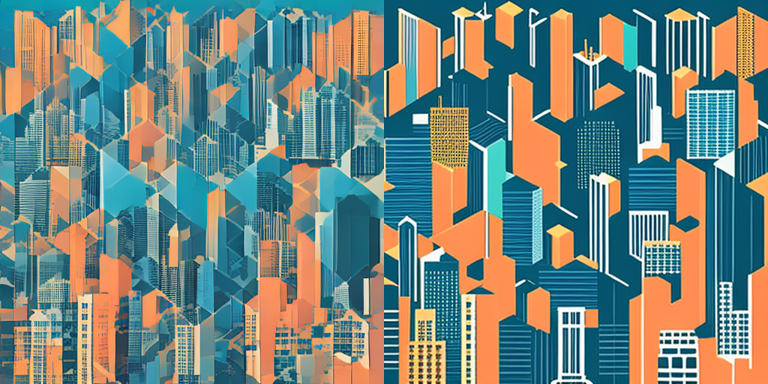

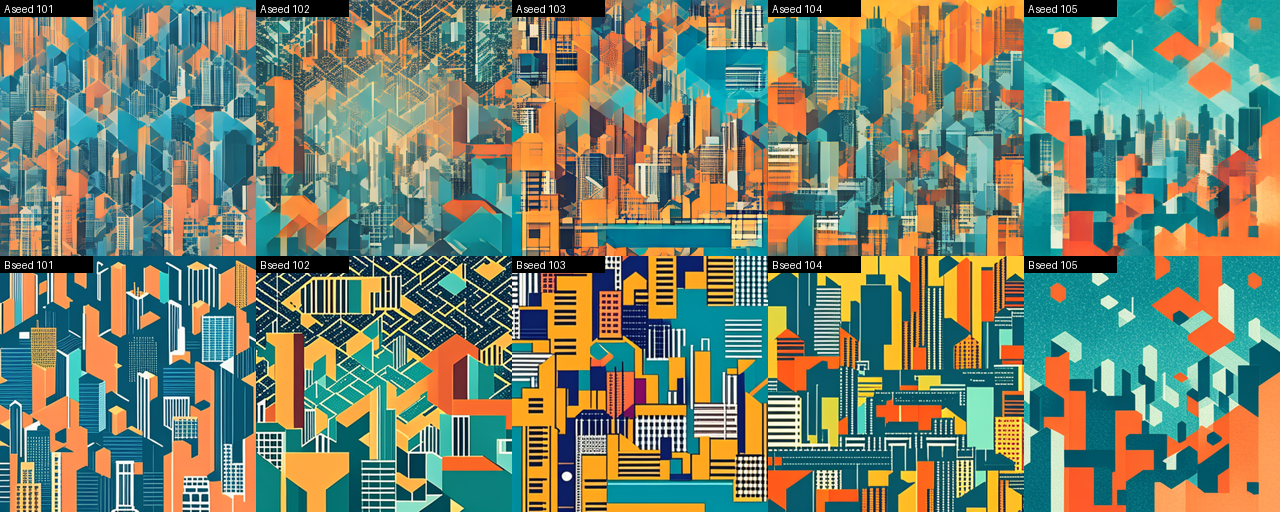

VISUAL_CHECK: {'a_layers_readable': False, 'b_layers_readable': False, 'seeds_a_readable': 1, 'seeds_b_readable': 2, 'notes': 'A: плотный коллаж из полупрозрачных наложенных фигур с фототекстурой окон, слои сливаются в мозаику; отдельная полоса силуэта видна только на seed 105. B: сплошные заливки и резкие края, ближе к flat style, но здания разбросаны сеткой по всему кадру, а не горизонтальными полосами; полосы читаются на seed 104 и 105, seed 102 превратился в изометрический узор. В B появились цвета вне палитры брифа (жёлтый, тёмно-синий, на seed 103 фиолетовый). Рост энергии границ в B вызван резкими краями заливок и сетками окон, а не шумом.'}


In [39]:
display(Image.open(artifacts / "comparison.png"))
display(seeds_sheet)

# Заполните только после фактического просмотра, затем перезапустите эту и последующие ячейки.
VISUAL_CHECK = {
    "a_layers_readable": False,
    "b_layers_readable": False,
    "seeds_a_readable": 1,
    "seeds_b_readable": 2,
    "notes": "A: плотный коллаж из полупрозрачных наложенных фигур с фототекстурой окон, слои сливаются в мозаику; "
             "отдельная полоса силуэта видна только на seed 105. "
             "B: сплошные заливки и резкие края, ближе к flat style, но здания разбросаны сеткой по всему кадру, "
             "а не горизонтальными полосами; полосы читаются на seed 104 и 105, seed 102 превратился в изометрический узор. "
             "В B появились цвета вне палитры брифа (жёлтый, тёмно-синий, на seed 103 фиолетовый). "
             "Рост энергии границ в B вызван резкими краями заливок и сетками окон, а не шумом.",
}
visual_done = all(VISUAL_CHECK[key] is not None for key in ("a_layers_readable", "b_layers_readable", "seeds_a_readable", "seeds_b_readable")) and bool(VISUAL_CHECK["notes"])
print("VISUAL_CHECK:", VISUAL_CHECK if visual_done else "PENDING")

In [40]:
# Намеренная ошибка демо на брифе варианта: ожидание, что guidance_scale = 1.0 «включает» guidance у SD Turbo.
x_g0 = L.generate(pipe, PROMPT, 101, guidance=0.0)[0]; cfg_g0 = pipe.do_classifier_free_guidance
x_g1 = L.generate(pipe, PROMPT, 101, guidance=1.0)[0]; cfg_g1 = pipe.do_classifier_free_guidance
x_g3 = L.generate(pipe, PROMPT, 101, guidance=3.0)[0]; cfg_g3 = pipe.do_classifier_free_guidance
sha_g0, sha_g1, sha_g3 = (L.sha(L.png_bytes(x)) for x in (x_g0, x_g1, x_g3))
intentional_error = {
    "description": "guidance_scale = 1.0 expected to enable classifier-free guidance in SD Turbo",
    "brief": BRIEF, "seed": 101, "steps": 1, "size": 512,
    "sha256_guidance_0": sha_g0, "sha256_guidance_1": sha_g1, "sha256_guidance_3": sha_g3,
    "guidance_1_equals_0_bitwise": sha_g0 == sha_g1,
    "cfg_active": {"0.0": cfg_g0, "1.0": cfg_g1, "3.0": cfg_g3},
    "psnr_guidance_1_vs_0_db": jnum(L.psnr_db(x_g0, x_g1)),
    "psnr_guidance_3_vs_0_db": jnum(L.psnr_db(x_g0, x_g3)),
    "diagnosis": "Diffusers enables CFG only when guidance_scale > 1; values 0..1 do not change the result",
    "fix": "study guidance only with values > 1 (factor 5 uses 3.0); do not transfer the conclusion to models with regular CFG",
}
(artifacts / "intentional_error.json").write_text(
    json.dumps(intentional_error, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("guidance 1.0: результат совпал с guidance 0.0 бит в бит:", sha_g0 == sha_g1, "| CFG активен:", cfg_g1)
print("guidance 3.0: CFG активен:", cfg_g3, "| PSNR относительно guidance 0.0, дБ:", round(L.psnr_db(x_g0, x_g3), 2))

guidance 1.0: результат совпал с guidance 0.0 бит в бит: True | CFG активен: False
guidance 3.0: CFG активен: True | PSNR относительно guidance 0.0, дБ: 10.89


In [41]:
# Паспорт эксперимента — все измеряемые поля берутся из этого сеанса.
pays_off = None
if visual_done:
    visual_gain = VISUAL_CHECK["b_layers_readable"] and not VISUAL_CHECK["a_layers_readable"]
    pays_off = classes["clip"] != "ухудшение" and (classes["clip"] == "улучшение" or visual_gain)

experiment_passport = {
    "status": "COMPLETE" if visual_done else "PARTIAL",
    "variant": VARIANT, "brief": BRIEF, "factor": FACTOR, "seeds": SEEDS,
    "hypothesis_recorded_at": HYPOTHESIS_RECORDED_AT,
    "hypothesis": "4 steps instead of 1 increase edge energy and contrast by more than 10 % and time by more than 20 %; CLIP similarity to the English brief changes within ±1.0",
    "tolerance": {m: {"kind": kind, "value": tol} for m, (kind, tol) in TOLERANCE.items()},
    "direction": {m: ("increase_is_improvement" if sign > 0 else "increase_is_deterioration") for m, sign in DIRECTION.items()},
    "decision_rule": "4 steps pay off if CLIP is 'improvement' or B passes the layers check while A does not, and CLIP is not 'deterioration'",
    "models": {
        "generator": {"model_id": L.MODEL_ID, "revision": L.REVISION, "dtype": "float16"},
        "clip": {"model_id": M.CLIP_ID, "revision": M.CLIP_REVISION},
    },
    "prompt": PROMPT, "clip_reference_text": PROMPT,
    "mode_a": A_CFG, "mode_b": B_CFG, "changed_fields": changed, "generator_device": "cpu",
    "environment": environment, "library_sha256": library_sha256,
    "timings_seconds": {"demo_total": round(demo_seconds, 2), "pipe_load": round(pipe_load_seconds, 2),
                        "clip_load": round(clip_load_seconds, 2), "variant_summary": round(summary_seconds, 2)},
    "metrics": metric_rows, "classification": classification,
    "deterministic_max_abs_diff": deterministic_max_abs_diff,
    "comparison_sheet_matches_series": same_as_series,
    "visual_check": VISUAL_CHECK, "pays_off": pays_off,
    "demo_reproduction": {"rows": demo_rows, "intentional_error": demo_error},
    "intentional_error": intentional_error,
    "limitations": [
        "one model, one brief, one factor, five seeds",
        "edge energy and contrast measure sharpness and tonal spread, not quality",
        "CLIP similarity reflects text alignment in CLIP space, not aesthetics; text is truncated to 77 tokens",
        "generation time depends on GPU state and is not reproduced exactly",
        "conclusions hold only for SD Turbo at the pinned revision and this environment",
    ],
    "license": "SD Turbo: Stability AI Community License Agreement, educational non-commercial use; CLIP: see model card at the pinned revision",
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(artifacts / "passport.json").write_text(
    json.dumps(experiment_passport, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

environment_lines = [
    "STATUS=ACTUAL", "execution_environment=Google Colab", f"actual_gpu={environment['gpu']}",
    f"cuda_runtime={environment['cuda_runtime']}", f"python={environment['python']}",
    *[f"{name}={version}" for name, version in environment["packages"].items()],
    f"platform={environment['platform']}", f"cuda_available={environment['cuda_available']}",
    *[f"environment_fix={fix}" for fix in ENVIRONMENT_FIXES],
    f"model={L.MODEL_ID}@{L.REVISION}", f"clip={M.CLIP_ID}@{M.CLIP_REVISION}",
]
(reports / "environment.txt").write_text("\n".join(environment_lines) + "\n", encoding="utf-8")
print(json.dumps({key: experiment_passport[key] for key in ("status", "timings_seconds", "pays_off")}, ensure_ascii=False, indent=2))

{
  "status": "COMPLETE",
  "timings_seconds": {
    "demo_total": 28.29,
    "pipe_load": 3.98,
    "clip_load": 1.96,
    "variant_summary": 6.5
  },
  "pays_off": false
}


In [42]:
# Итоговая проверка файлов, JSON, PNG и чек-листа методички.
required_files = [
    artifacts / "metrics.json", artifacts / "per_seed_metrics.csv", artifacts / "classification.json",
    artifacts / "comparison.png", artifacts / "comparison_all_seeds.png",
    artifacts / "seed101_A.png", artifacts / "seed101_B.png",
    artifacts / "intentional_error.json", artifacts / "demo" / "demo_variant01.json",
    artifacts / "passport.json", reports / "environment.txt",
]
for path in required_files:
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"
for path in required_files:
    if path.suffix == ".json":
        json.loads(path.read_text(encoding="utf-8"))
for path, size in [(artifacts / "comparison.png", (768, 384)), (artifacts / "seed101_A.png", (512, 512)), (artifacts / "seed101_B.png", (512, 512))]:
    with Image.open(path) as check_image:
        check_image.verify()
    with Image.open(path) as check_image:
        assert check_image.format == "PNG" and check_image.size == size, (path, check_image.size)

assert len(metric_rows) == 4 and len(per_seed_df) == 2 * len(SEEDS)
assert changed == ["steps"]
assert intentional_error["guidance_1_equals_0_bitwise"] and not intentional_error["cfg_active"]["1.0"]
assert VISUAL_CHECK is not None and visual_done, "Заполните VISUAL_CHECK после фактического просмотра"
assert experiment_passport["status"] == "COMPLETE"

checklist = {
    "hypothesis_and_tolerance_before_run": True,
    "actual_gpu_and_versions_recorded": True,
    "libraries_match_methodology_sha256": library_sha256 == EXPECTED_SHA256,
    "exactly_one_factor_changed": changed == ["steps"],
    "five_seed_series": list(M.SEEDS) == SEEDS,
    "clip_against_english_brief": True,
    "metrics_table_saved": True,
    "comparison_png_saved": True,
    "classification_by_tolerance_saved": True,
    "demo_variant_executed_and_compared": bool(demo_rows),
    "guidance_error_reproduced": intentional_error["guidance_1_equals_0_bitwise"],
    "visual_city_layers_checked": visual_done,
    "passport_complete": experiment_passport["status"] == "COMPLETE",
}
print(json.dumps(checklist, ensure_ascii=False, indent=2))
assert all(checklist.values())
print("FULL CHECKLIST: PASS")

{
  "hypothesis_and_tolerance_before_run": true,
  "actual_gpu_and_versions_recorded": true,
  "libraries_match_methodology_sha256": true,
  "exactly_one_factor_changed": true,
  "five_seed_series": true,
  "clip_against_english_brief": true,
  "metrics_table_saved": true,
  "comparison_png_saved": true,
  "classification_by_tolerance_saved": true,
  "demo_variant_executed_and_compared": true,
  "guidance_error_reproduced": true,
  "visual_city_layers_checked": true,
  "passport_complete": true
}
FULL CHECKLIST: PASS


In [43]:
# Архив результатов для переноса в репозиторий: artifacts/, reports/ и записанные библиотеки.
import zipfile
with zipfile.ZipFile("lab06_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted([*artifacts.rglob("*"), *reports.rglob("*")]):
        if path.is_file():
            archive.write(path)
    for name in EXPECTED_SHA256:
        archive.write(name)
print("lab06_results.zip:", round(pathlib.Path("lab06_results.zip").stat().st_size / 1024), "KiB")
try:
    from google.colab import files
    files.download("lab06_results.zip")
except ImportError:
    pass

lab06_results.zip: 7133 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>